In [32]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [33]:
class BMIState(TypedDict):
    weight : float
    height : float
    bmi : float
    fitness : str


In [34]:
def calculate_bmi(state:BMIState) -> BMIState:
    weight = state['weight']
    height = state['height']
    print(weight)
    state['bmi'] = round(weight / (height**2),2)
    return state

In [35]:
def label_bmi(state:BMIState) -> BMIState:
    if state["bmi"] < 18:
        state["fitness"] = "Under weight"
    elif state["bmi"] > 24:
        state["fitness"] = "Over Weight"
    else:
        state["fitness"] = "Fit"
    return state
    

In [36]:
graph = StateGraph(BMIState)
graph.add_node('calculate_bmi',calculate_bmi)
graph.add_node('check_fitness', label_bmi)
graph.add_edge(START, 'calculate_bmi')
graph.add_edge('calculate_bmi', 'check_fitness')
graph.add_edge('check_fitness', END)
workflow = graph.compile()


In [37]:
workflow.invoke({'weight': 65, 'height' : 1.75})

65


{'weight': 65, 'height': 1.75, 'bmi': 21.22, 'fitness': 'Fit'}

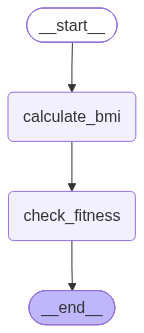

In [38]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())